# 04 · Entangling a particle's $x$ and $y$ motions with a two-tone drive

Can the two transverse motions of one levitated particle, coupled to one cavity mode by coherent
scattering, be entangled in the steady state? This notebook reproduces the core numbers of
levisim's two-tone study at the parameters measured by Deplano *et al.*, Nat. Commun. **16**, 4215
(2025): one tone never entangles; a red and a blue tone together engineer a two-mode-squeezed
reservoir; at the published heating it is still not enough, and the threshold is about half the
published heating.

**Runtime:** about 10 s. **Background:** the full study,
[Steady-state entanglement with a two-tone drive](../../docs/two_tone_entanglement/README.md), which
derives the scheme step by step, explains the choice of entanglement measure, and covers what this
notebook leaves out (trap beat, tone-frequency locking, build-up, polarisation).

In [ ]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq, minimize_scalar

from levisim.analysis.gaussian_states import (
    log_negativity,
    mean_phonon_numbers,
    partially_transposed_symplectic_eigenvalues,
)
from levisim.core.plotting import set_plt_rcParams_to_xmgrace_style
from levisim.core.units import kHz
from levisim.multiphysics.covariance import dimension_covariance, steady_state_covariance
from levisim.multiphysics.two_tone import (
    DEPLANO2025,
    analytic_optimum,
    analytic_threshold_cooperativity,
    deplano2025_multitrap,
    quantum_cooperativity,
    two_tone_rwa_steady_state,
    two_tone_steady_state,
)

set_plt_rcParams_to_xmgrace_style()

## 1. The system

`deplano2025_multitrap` builds a one-particle, two-axis `MultiTrap` with the published trap
frequencies, couplings, cavity linewidth and detuning. levisim's bath is gas damping at 300 K, so
the fitted heating rates $\Gamma_j\bar n_j$ are reproduced by choosing $\Gamma_j$; `Γ_scale` divides
them ("heating Γ/3"). `balanced=True` replaces $g_x$, $g_y$ by their RMS value, which is what the
scheme wants (section 5 uses the published, unbalanced ones). The quantum cooperativity
$C = 4G^2/(\kappa\,\Gamma\bar n)\cdot[1 + (\delta/\kappa)^2]^{-1}$, with $\delta = \Omega_x - \Omega_y$, is the
figure of merit.

In [ ]:
p = DEPLANO2025
print(f"Ω_x/2π = {p['Ωx'] / kHz:.2f} kHz, Ω_y/2π = {p['Ωy'] / kHz:.2f} kHz, g_x/2π = {p['gx'] / kHz:.2f} kHz,"
      f" g_y/2π = {p['gy'] / kHz:.2f} kHz")
print(f"Γ_x n_x/2π = {p['Γx_decoherence'] / kHz:.2f} kHz, Γ_y n_y/2π = {p['Γy_decoherence'] / kHz:.2f} kHz,"
      f" κ/2π = {p['κ'] / kHz:.0f} kHz, Δ/2π = {p['Δ'] / kHz:.0f} kHz  ({p['reference']})")

mtrap = deplano2025_multitrap(balanced=True)
C_published = quantum_cooperativity(mtrap)
print(f'\nbalanced couplings g/2π = {abs(mtrap.dimensions["x1"].g) / kHz:.2f} kHz;'
      f' cooperativity at the published heating C = {C_published:.2f}')

Ω_x/2π = 122.17 kHz, Ω_y/2π = 109.37 kHz, g_x/2π = 14.13 kHz, g_y/2π = 10.37 kHz
Γ_x n_x/2π = 4.03 kHz, Γ_y n_y/2π = 3.05 kHz, κ/2π = 57 kHz, Δ/2π = -111 kHz  (Deplano et al., Nat. Commun. 16, 4215 (2025), Table 1)

balanced couplings g/2π = 12.39 kHz; cooperativity at the published heating C = 2.90


## 2. One tone: phonon exchange, never entanglement

With a single red-detuned tone, the cavity mediates *exchange* of phonons between $x$ and $y$
($\hat b_x^\dagger \hat b_y$), but making a *pair* ($\hat b_x^\dagger \hat b_y^\dagger$) costs
$\hbar(\Omega_x + \Omega_y)$, which one tone cannot supply resonantly. Entanglement is decided by the
smallest symplectic eigenvalue $\tilde\nu_-$ of the partially transposed $x$-$y$ covariance matrix: the
state is entangled if and only if $\tilde\nu_- < 1$, and the logarithmic negativity is
$E_N = \max(0, -\ln\tilde\nu_-)$. The single-tone steady state comes from the Lyapunov equation:

In [ ]:
Ω_bar = (p['Ωx'] + p['Ωy']) / 2
print('heating      ν̃_-     n_x     n_y')
for Γ_scale, name in ((1, 'published'), (1 / 3, 'Γ/3'), (1 / 10, 'Γ/10'), (1e-6, 'Γ × 1e-6')):
    single = deplano2025_multitrap(Γ_scale=Γ_scale, Δ=-Ω_bar)   # one tone, red-detuned by Ω̄
    V = dimension_covariance(single, steady_state_covariance(single), ['x1', 'y1'])
    n_x, n_y = mean_phonon_numbers(V)
    print(f'{name:10s} {partially_transposed_symplectic_eigenvalues(V).min():6.3f}  {n_x:6.3f}  {n_y:6.3f}')

heating      ν̃_-     n_x     n_y
published   2.004   0.552   0.686
Γ/3         1.379   0.199   0.243
Γ/10        1.144   0.075   0.088
Γ × 1e-6    1.032   0.022   0.022


$\tilde\nu_-$ never drops below 1, even with the heating switched off: one tone leaves $x$ and $y$
separable, however cold. (The correlations Deplano *et al.* measured, a Gaussian discord of about
0.04, are exchange correlations of a separable state.)

## 3. Two tones: a two-mode-squeezed reservoir

Put a red tone at $\omega_c - \bar\Omega$ and a weaker blue tone at $\omega_c + \bar\Omega$,
$\bar\Omega = (\Omega_x + \Omega_y)/2$, keeping the total power fixed. A photon emitted at
$\omega_c + \delta/2$ then no longer tells whether an $x$ phonon was removed (red tone, anti-Stokes) or
a $y$ phonon was added (blue tone, Stokes), so the cavity damps the Bogoliubov modes
$\hat\beta_1 \propto \hat b_x + \tanh r\,\hat b_y^\dagger$ and $\hat\beta_2 \propto \hat b_y + \tanh r\,\hat b_x^\dagger$,
$\tanh r = G_+/G_-$, whose joint vacuum is the two-mode squeezed vacuum with $E_N = 2r$.

`two_tone_steady_state` propagates the covariance matrix over one period of the drive (a Floquet
treatment that keeps every counter-rotating term); `two_tone_rwa_steady_state` is the
rotating-wave model. Sweep the amplitude ratio $G_+/G_-$ at three heating levels:

heating published: best E_N on the grid 0.000 at G+/G- = 0.050 (RWA 0.000)
heating Γ/3      : best E_N on the grid 0.176 at G+/G- = 0.525 (RWA 0.249)
heating Γ/10     : best E_N on the grid 0.766 at G+/G- = 0.675 (RWA 0.942)


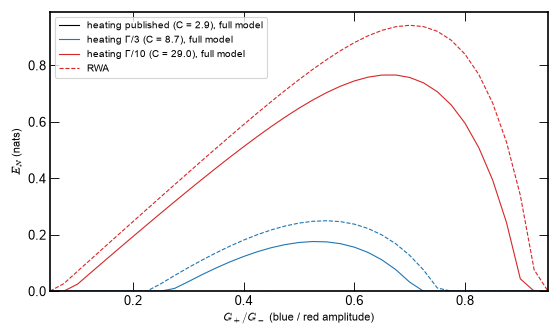

In [ ]:
def E_N_full(mtrap, ratio):
    state = two_tone_steady_state(mtrap, ratio)
    return state.E_N if state.stable else np.nan          # period-averaged E_N

def E_N_rwa(mtrap, ratio):
    stable, _, V = two_tone_rwa_steady_state(mtrap, ratio)
    return log_negativity(V) if stable else np.nan

ratios = np.arange(0.05, 0.951, 0.025)
heatings = {'published': 1, 'Γ/3': 1 / 3, 'Γ/10': 1 / 10}
colours = {'published': 'k', 'Γ/3': 'tab:blue', 'Γ/10': 'tab:red'}
sweep = {}
for name, Γ_scale in heatings.items():
    mt = deplano2025_multitrap(Γ_scale=Γ_scale, balanced=True)
    sweep[name] = ([E_N_full(mt, r) for r in ratios], [E_N_rwa(mt, r) for r in ratios], quantum_cooperativity(mt))

fig, ax = plt.subplots(figsize=(7, 4.2))
for name, (full, rwa, C) in sweep.items():
    ax.plot(ratios, full, '-', color=colours[name], label=f'heating {name} (C = {C:.1f}), full model')
    ax.plot(ratios, rwa, '--', color=colours[name], lw=1, label='RWA' if name == 'Γ/10' else None)
ax.set_xlim(ratios[0], ratios[-1])
ax.set_ylim(bottom=0)
ax.set_xlabel(r'$G_+/G_-$ (blue / red amplitude)')
ax.set_ylabel(r'$E_N$ (nats)')
ax.legend(fontsize=9, loc='upper left')
fig.tight_layout()
for name, (full, rwa, C) in sweep.items():
    k = int(np.nanargmax(full))
    print(f'heating {name:9s}: best E_N on the grid {full[k]:.3f} at G+/G- = {ratios[k]:.3f}'
          f' (RWA {np.nanmax(rwa):.3f})')

At the published heating $E_N = 0$ for every ratio. At a third of it the best value is 0.18 (at
$G_+/G_- \approx 0.53$), at a tenth 0.77 (at about 0.66-0.68). Two effects compete as the blue tone
grows: more squeezing ($r$ grows), but more heating noise reaches the Bogoliubov modes
($\propto\cosh 2r$) while the cooling rate falls ($\propto 1/\cosh 2r$ at fixed power). The RWA
(dashed) overestimates $E_N$ because it drops the red tone's Stokes and the blue tone's anti-Stokes
sidebands, which here ($\kappa/\bar\Omega = 0.49$) are suppressed but not absent.

## 4. The threshold

In the ideal limit (RWA, balanced couplings, Bogoliubov modes resolved but inside the cavity line)
the optimum over $r$ is $E_N^* = \ln[C/(2\sqrt{1+C})]$, so entanglement needs
$C > C_\text{th} = 2 + 2\sqrt2 \approx 4.83$. Optimise $G_+/G_-$ at each heating level for the RWA and
the full model, and find where each first entangles. The full model's $E_N$ oscillates over the
drive period, so its threshold is where $\tilde\nu_- < 1$ is first reached at *some* instant (where
levisim's period-averaged $E_N$ first becomes positive).

In [ ]:
def best_log_negativity(Γ_scale, model, balanced=True):
    # max over G+/G- of -ln ν̃_- (not clipped at 0, so it can be root-found); returns (value, best ratio)
    mt = deplano2025_multitrap(Γ_scale=Γ_scale, balanced=balanced)
    def objective(ratio):
        if model == 'rwa':
            stable, _, V = two_tone_rwa_steady_state(mt, ratio)
            return np.log(partially_transposed_symplectic_eigenvalues(V).min()) if stable else np.inf
        state = two_tone_steady_state(mt, ratio)
        return np.min(np.log(state.ν_tildes)) if state.stable else np.inf   # most entangled instant
    result = minimize_scalar(objective, bounds=(0.05, 0.95), method='bounded', options=dict(xatol=1e-4))
    return -result.fun, result.x

thresholds = {}
for model in ('full', 'rwa'):
    log_scale = brentq(lambda s: best_log_negativity(10**s, model)[0], np.log10(1 / 1.5), np.log10(1 / 3), xtol=1e-5)
    thresholds[model] = 10**-log_scale
log_scale = brentq(lambda s: best_log_negativity(10**s, 'full', balanced=False)[0], np.log10(1 / 1.5), np.log10(1 / 3.5), xtol=1e-5)
C_unbalanced = quantum_cooperativity(deplano2025_multitrap())
print(f'ideal reservoir: C_th = {analytic_threshold_cooperativity():.2f}, i.e. heating ÷ {analytic_threshold_cooperativity() / C_published:.2f}')
print(f'RWA            : C_th = {C_published * thresholds["rwa"]:.2f}, i.e. heating ÷ {thresholds["rwa"]:.2f}')
print(f'full model     : C_th = {C_published * thresholds["full"]:.2f}, i.e. heating ÷ {thresholds["full"]:.2f}')
print(f'full model, published (unbalanced) couplings: C_th = {C_unbalanced * 10**-log_scale:.2f}, i.e. heating ÷ {10**-log_scale:.2f}')

ideal reservoir: C_th = 4.83, i.e. heating ÷ 1.67
RWA            : C_th = 5.84, i.e. heating ÷ 2.02
full model     : C_th = 6.20, i.e. heating ÷ 2.14
full model, published (unbalanced) couplings: C_th = 6.91, i.e. heating ÷ 2.38


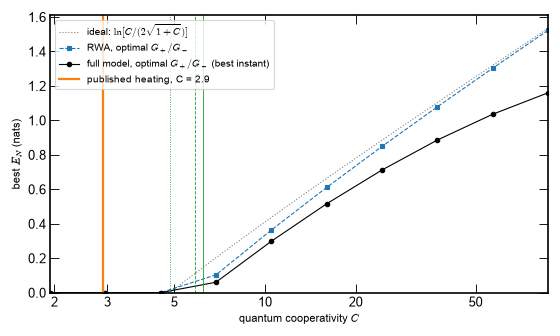

In [ ]:
Γ_scales = np.geomspace(1.5, 1 / 30, 10)
C_values = C_published / Γ_scales
best_full = [max(0, best_log_negativity(s, 'full')[0]) for s in Γ_scales]
best_rwa = [max(0, best_log_negativity(s, 'rwa')[0]) for s in Γ_scales]
C_fine = np.geomspace(C_values[0], C_values[-1], 200)
ideal = [analytic_optimum(C)[1] for C in C_fine]

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.semilogx(C_fine, ideal, ':', color='grey', label=r'ideal: $\ln[C/(2\sqrt{1+C})]$')
ax.semilogx(C_values, best_rwa, 's--', ms=4, color='tab:blue', label='RWA, optimal $G_+/G_-$')
ax.semilogx(C_values, best_full, 'o-', ms=4, color='k', label='full model, optimal $G_+/G_-$ (best instant)')
for C, style in ((analytic_threshold_cooperativity(), ':'), (C_published * thresholds['rwa'], '--'), (C_published * thresholds['full'], '-')):
    ax.axvline(C, ls=style, lw=0.8, color='tab:green')
ax.axvline(C_published, color='tab:orange', lw=2, label=f'published heating, C = {C_published:.1f}')
ax.set_xlim(C_fine[0], C_fine[-1])
ax.set_ylim(bottom=0)
ax.set_xticks([2, 3, 5, 10, 20, 50], ['2', '3', '5', '10', '20', '50'])
ax.minorticks_off()
ax.set_xlabel('quantum cooperativity $C$')
ax.set_ylabel(r'best $E_N$ (nats)')
ax.legend(fontsize=9, loc='upper left')
fig.tight_layout()

Green lines: the three thresholds. The published experiment ($C = 2.9$) sits a factor of about 2
below the full-model threshold ($C \approx 6.2$), and the counter-rotating terms cost a further 20-30%
of $E_N$ relative to the RWA above it. At large $C$, $E_N^* \approx \tfrac12\ln(C/4)$: each factor
$e^2 \approx 7.4$ in cooperativity buys one nat.

## 5. Within one drive period

The counter-rotating terms make the steady state periodic rather than stationary. At heating
Γ/10 and $G_+/G_- = 0.675$:

G+/G- = 0.675: E_N = 0.7656 (min 0.7441, max 0.7859), n = [1.001 0.975], 〈β†β〉 = (0.420, 0.394), |Floquet multiplier| = 0.8914
E_N over the sampled window: 0.744 to 0.786; |Floquet multiplier| 0.891 < 1 (stable)


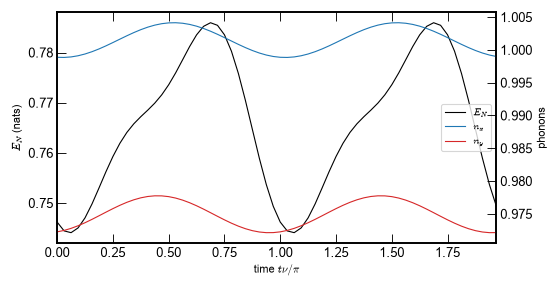

In [ ]:
mt = deplano2025_multitrap(Γ_scale=1 / 10, balanced=True)
state = two_tone_steady_state(mt, 0.675, num_samples=64)
phase = state.times * state.ν / np.pi            # in units of π/ν
n = np.array([mean_phonon_numbers(V) for V in state.mechanical_covariances])

fig, ax1 = plt.subplots(figsize=(7, 3.6))
ax1.plot(phase, state.log_negativities, 'k-', label='$E_N$')
ax1.set_xlabel(r'time $t\nu/\pi$')
ax1.set_ylabel('$E_N$ (nats)')
ax2 = ax1.twinx()
ax2.plot(phase, n[:, 0], color='tab:blue', lw=1, label='$n_x$')
ax2.plot(phase, n[:, 1], color='tab:red', lw=1, label='$n_y$')
ax2.set_ylabel('phonons')
ax1.set_xlim(phase[0], phase[-1])
lines = ax1.get_lines() + ax2.get_lines()
ax1.legend(lines, [line.get_label() for line in lines], fontsize=9, loc='center right')
fig.tight_layout()
print(state.summary_str)
print(f'E_N over the sampled window: {state.E_N_min:.3f} to {state.E_N_max:.3f}; |Floquet multiplier| {state.floquet_multiplier:.3f} < 1 (stable)')

Over the sampled window, $E_N$ repeats every $\pi/\nu$ and breathes by about ±3% around 0.77,
and each motion holds about one phonon - more than ten times the single-tone state at the same
heating (0.08-0.09 phonons, section 2), because each half of a two-mode squeezed state is locally
thermal. An entangled two-tone state looks *hotter* to
single-mode thermometry than the separable state it was made from.

The numbers here agree with the study's results table: best $E_N$ 0.18 at Γ/3 and 0.77 at Γ/10;
thresholds $C$ = 4.83 / 5.85 / 6.21 there and 4.83 / 5.84 / 6.20 here, the last digit depending on
the optimiser's tolerance and the 16 time samples per period. What the study adds - the trap beat of co-polarised tones, the
frequency-locking tolerances, the build-up time, and why discord, Duan's criterion or a
phase-averaged covariance matrix mislead - is in
[the README](../../docs/two_tone_entanglement/README.md) and
[its follow-up on polarisation and a second particle](../../docs/two_tone_entanglement/polarisation_and_two_particles.md).